<a href="https://colab.research.google.com/github/Revathi2990/Excel-coding-challenge/blob/main/Python_DA_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Data Visualization**

In [1]:
import seaborn as sns


# Load the 'taxis' dataset
df = sns.load_dataset("taxis")


# Display the dataset
print(df)


                  pickup             dropoff  passengers  distance  fare  \
0    2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0   
1    2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0   
2    2019-03-27 17:53:01 2019-03-27 18:00:25           1      1.37   7.5   
3    2019-03-10 01:23:59 2019-03-10 01:49:51           1      7.70  27.0   
4    2019-03-30 13:27:42 2019-03-30 13:37:14           3      2.16   9.0   
...                  ...                 ...         ...       ...   ...   
6428 2019-03-31 09:51:53 2019-03-31 09:55:27           1      0.75   4.5   
6429 2019-03-31 17:38:00 2019-03-31 18:34:23           1     18.74  58.0   
6430 2019-03-23 22:55:18 2019-03-23 23:14:25           1      4.14  16.0   
6431 2019-03-04 10:09:25 2019-03-04 10:14:29           1      1.12   6.0   
6432 2019-03-13 19:31:22 2019-03-13 19:48:02           1      3.85  15.0   

       tip  tolls  total   color      payment            pickup_zone  \
0     2.15    0

In [2]:
# 1. Check for missing values in each column
print("Missing values in each column:")
print(df.isnull().sum())


# Identify columns that contain missing values
print("\nColumns with missing data:")
print(df.columns[df.isnull().any()].tolist())


# 2. Impute missing values


# Numerical columns: fill with median
for col in df.select_dtypes(include="number").columns:
  if df[col].isnull().any():
    df[col] = df[col].fillna(df[col].median())



#Categorical columns: fill with mode
for col in df.select_dtypes(include=["object", "category"]).columns:
     if df[col].isnull().any():
        mode_value = df[col].mode()
        if not mode_value.empty:
           df[col] = df[col].fillna(mode_value[0])


# 3. Remove rows with missing values in critical columns
# Example: pickup and dropoff timestamps are critical
df.dropna(subset=["pickup", "dropoff"], inplace=True)


# 4. Verify missing values after handling
print("\nMissing values after handling:")
print(df.isnull().sum())

print("\nFinal dataset shape:", df.shape)










Missing values in each column:
pickup              0
dropoff             0
passengers          0
distance            0
fare                0
tip                 0
tolls               0
total               0
color               0
payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64

Columns with missing data:
['payment', 'pickup_zone', 'dropoff_zone', 'pickup_borough', 'dropoff_borough']

Missing values after handling:
pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64

Final dataset shape: (6433, 14)


**Visualizations using Matplotlib/Pandas Plot**

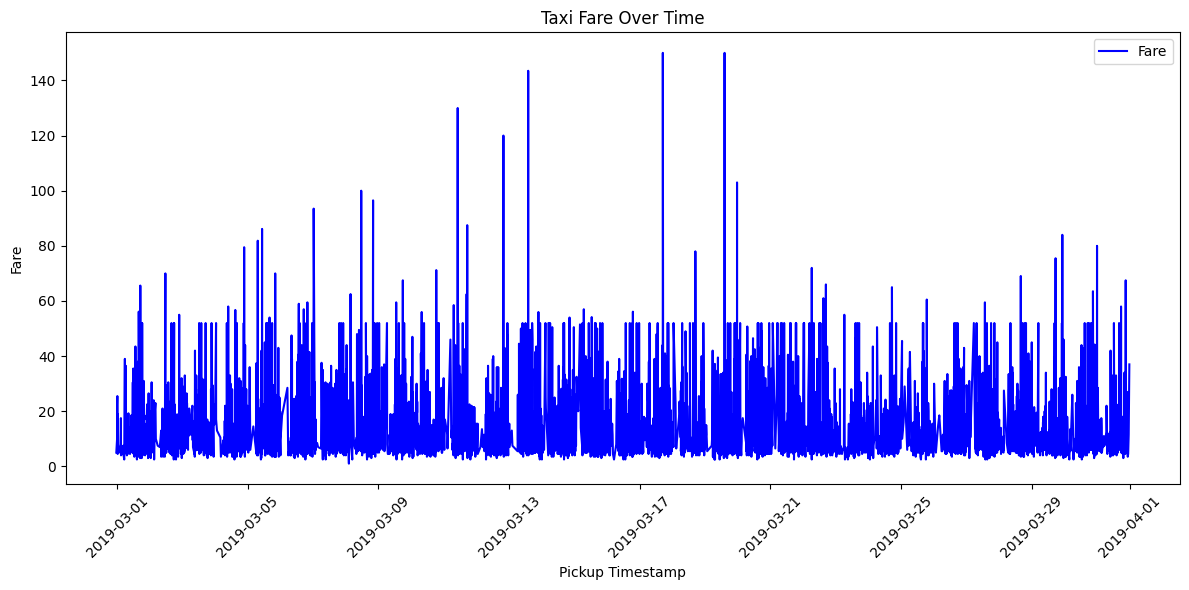

In [3]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")


# Convert pickup column to datetime format
df['pickup'] = pd.to_datetime(df['pickup'])


# Sort data by pickup timestamp
df = df.sort_values(by='pickup')

# Plot the line chart
plt.figure(figsize=(12, 6))
plt.plot(df['pickup'], df['fare'], label='Fare', color='blue')

# Add chart details
plt.xlabel('Pickup Timestamp')
plt.ylabel('Fare')
plt.title('Taxi Fare Over Time')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

# Display the chart
plt.show()




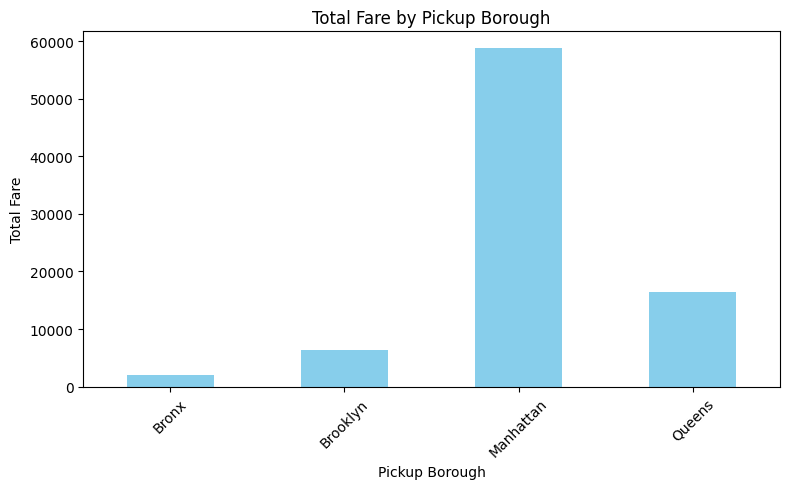

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Group by pickup_borough and calculate total fare
borough_fare = df.groupby("pickup_borough")["fare"].sum()

# Create the bar chart
borough_fare.plot(kind="bar", figsize=(8, 5), color="skyblue")

# Add chart labels and title
plt.title("Total Fare by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.xticks(rotation=45)
plt.tight_layout()


# Display the chart
plt.show()




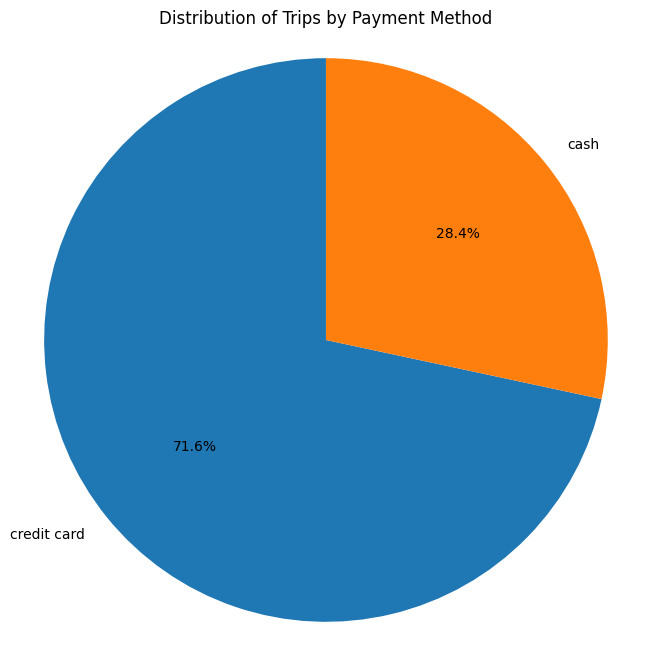

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt


# Load the taxis dataset
df = sns.load_dataset("taxis")

# Count trips for each payment method
payment_counts = df['payment'].value_counts()


# Plot the pie chart
plt.figure(figsize=(8, 8))
plt.pie(
       payment_counts,
       labels=payment_counts.index,
        autopct='%1.1f%%',
       startangle=90

)


plt.title('Distribution of Trips by Payment Method')
plt.axis('equal')
plt.show()



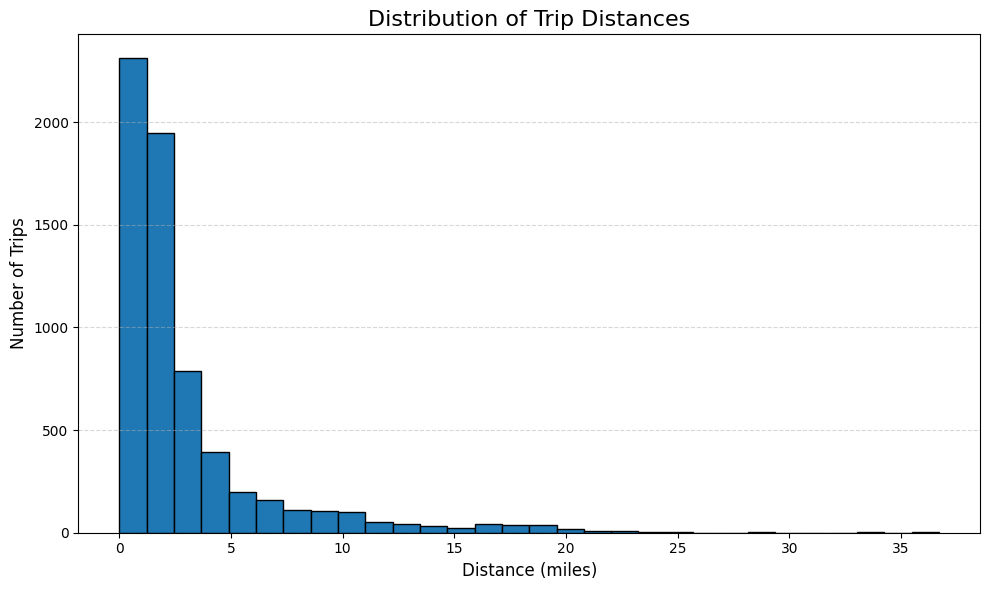

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt


# Load the taxis dataset
df = sns.load_dataset("taxis")

# Remove missing values from distance
distance = df["distance"].dropna()

# Create histogram
plt.figure(figsize=(10, 6))
plt.hist(distance, bins=30, edgecolor="black")

# Customize the plot
plt.title("Distribution of Trip Distances", fontsize=16)
plt.xlabel("Distance (miles)", fontsize=12)
plt.ylabel("Number of Trips", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Display the histogram
plt.tight_layout()
plt.show()


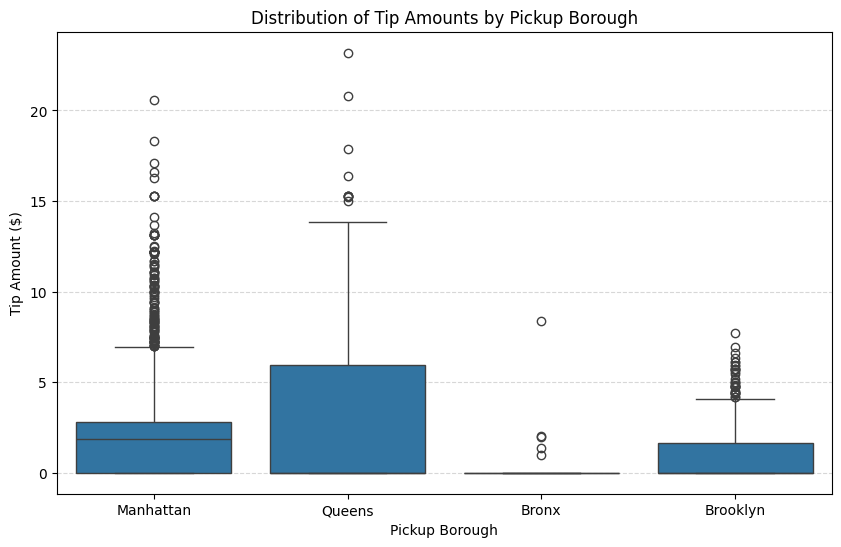

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Create the box plot
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="pickup_borough", y="tip")

# Customize the plot
plt.title("Distribution of Tip Amounts by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount ($)")
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Display the plot
plt.show()


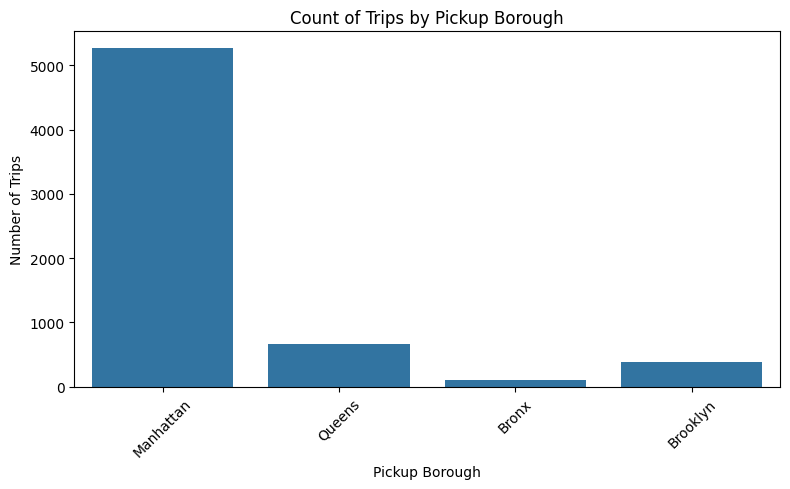

In [8]:
import seaborn as sns
import matplotlib.pyplot as plt


# Load the taxis dataset
df = sns.load_dataset("taxis")

# Create a count plot
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="pickup_borough")

# Add labels and title
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")
plt.title("Count of Trips by Pickup Borough")


plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

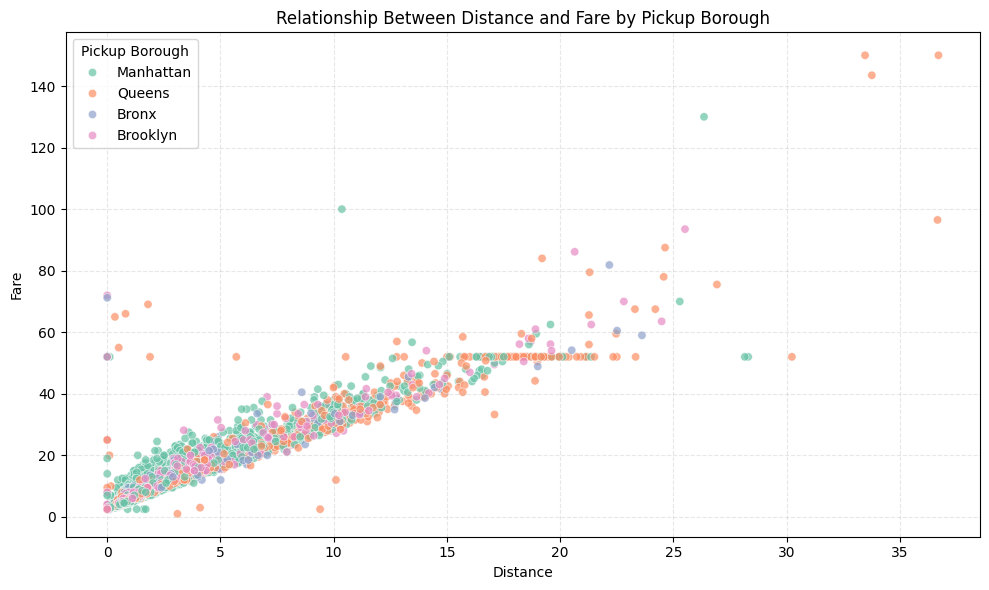

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough",
    palette="Set2",
    alpha=0.7

)

# Add title and labels
plt.title("Relationship Between Distance and Fare by Pickup Borough")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.legend(title="Pickup Borough")
plt.grid(True, linestyle="--", alpha=0.3)

# Display the plot
plt.tight_layout()
plt.show()


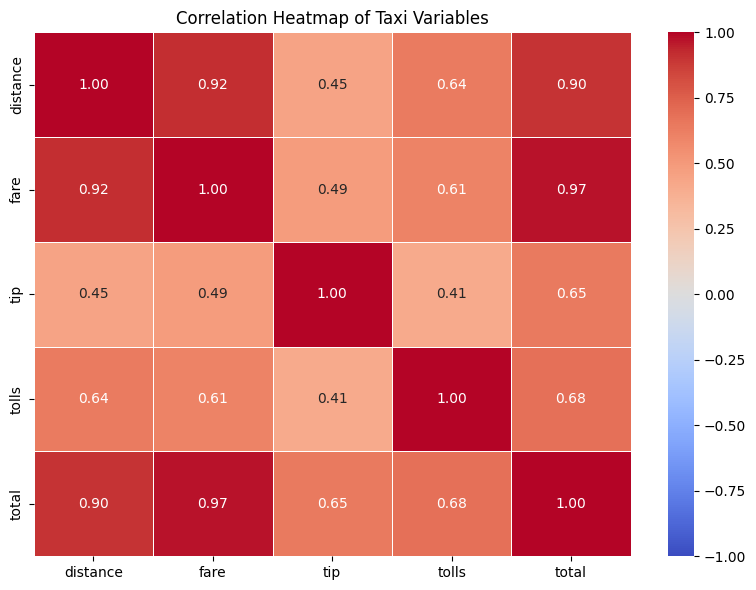

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Select numerical columns
numerical_cols = ['distance', 'fare', 'tip', 'tolls', 'total']

# Calculate the correlation matrix
correlation_matrix = df[numerical_cols].corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Taxi Variables')
plt.tight_layout()
plt.show()




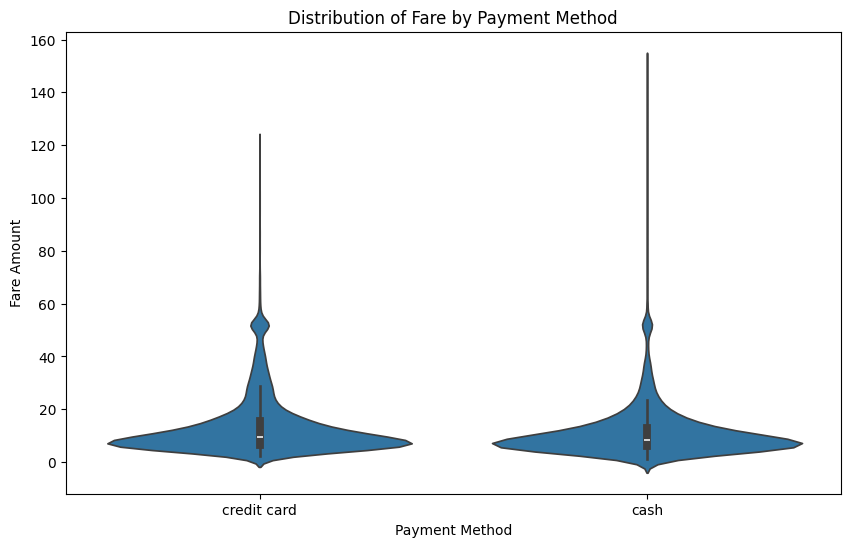

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

# Load the taxis dataset
df = sns.load_dataset("taxis")

# Create the violin plot
plt.figure(figsize=(10, 6))
sns.violinplot(data=df, x="payment", y="fare")


# Add title and labels
plt.title("Distribution of Fare by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare Amount")

# Display the plot
plt.show()